# Question 1

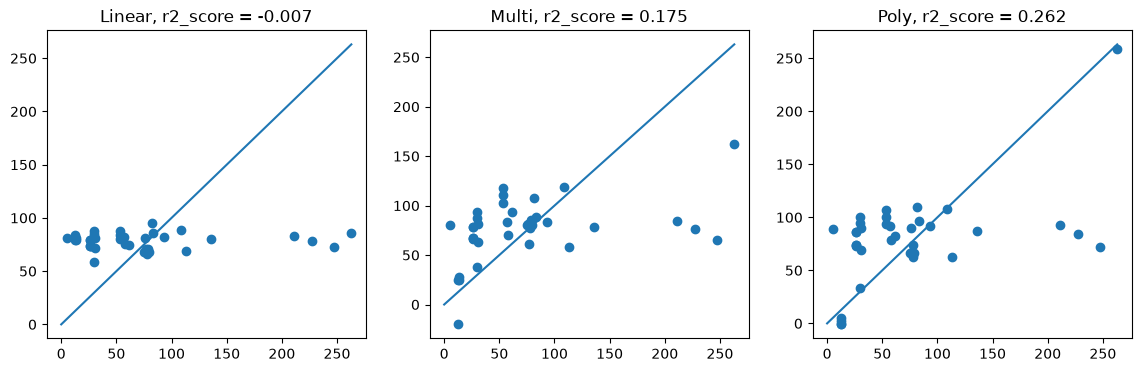

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("titanic.csv")
df = df.dropna()

df = df.sample(frac=1, random_state=42)

x = df[["Age", "Pclass", "SibSp"]].values
y = df["Fare"].values

n = int(len(df)*0.8)
x_train, x_test, y_train, y_test = x[:n], x[n:], y[:n], y[n:]


def linear(x_train, y_train, x_test):
    x_train = np.column_stack([np.ones(len(x_train)), x_train])
    x_test = np.column_stack([np.ones(len(x_test)), x_test])
    w = np.linalg.pinv(x_train.T @ x_train) @ x_train.T @ y_train
    return x_test @ w


def boost(X_train, y_train, X_test):
    pred_train = np.full(len(y_train), y_train.mean())
    pred_test = np.full(len(X_test), y_train.mean())
    for _ in range(50):
        error = y_train - pred_train
        best = 1e18
        for j in range(X_train.shape[1]):
            for t in np.unique(X_train[:, j])[:-1]:
                left = X_train[:, j] <= t
                right = X_train[:, j] > t
                a, b = error[left].mean(), error[right].mean()
                fix_train = np.where(left, a, b)
                loss = ((error - fix_train) ** 2).sum()
                if loss < best:
                    best, best_train, best_test = loss, fix_train, np.where(X_test[:, j] <= t, a, b)
        pred_train += 0.1 * best_train
        pred_test += 0.1 * best_test
    return pred_test
    
def show(pos, name, y_pred):
    plt.subplot(1,3, pos)
    r2_score = 1- (((y_test-y_pred)**2).sum() / ((y_test-y_test.mean()) ** 2).sum())
    plt.title(f"{name}, r2_score = {round(r2_score, 3)}")
    plt.scatter(y_test, y_pred)
    plt.plot([0, y_test.max()], [0, y_test.max()])

plt.figure(figsize=(14,4))
show(1, "Linear", linear(x_train[:, :1], y_train, x_test[:, :1]))
show(2, "Multi", linear(x_train, y_train, x_test))
show(3, "Poly", linear(np.column_stack([x_train, x_train**2]), y_train, np.column_stack([x_test, x_test**2])))
# show("Linear", linear(x_train[:, :1], y_train, x_test))

# Question 2

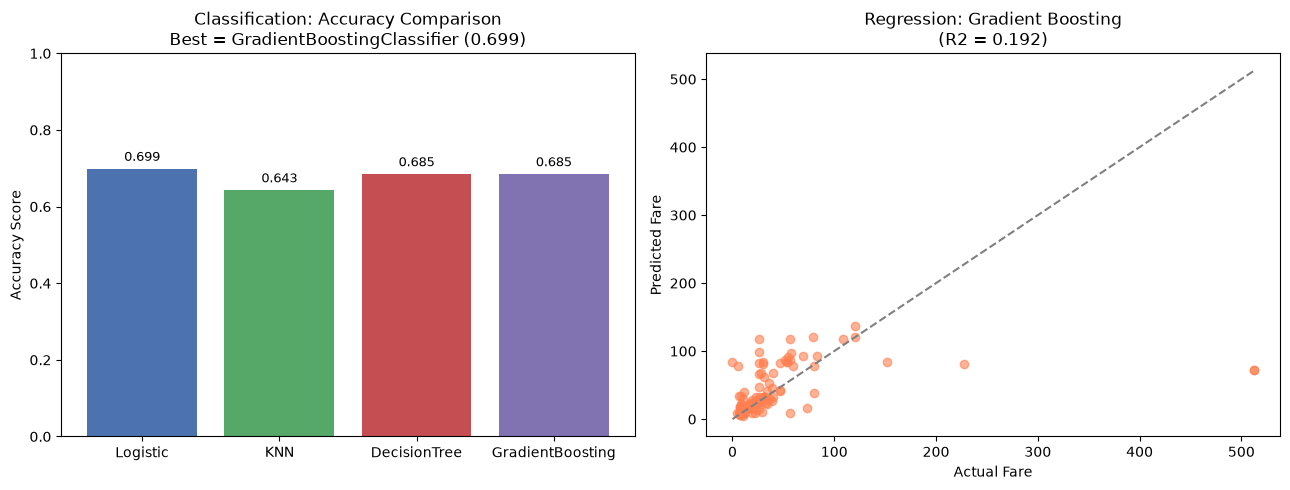

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, r2_score

# 1. Load and clean
df = pd.read_csv("titanic.csv")
cols = ["Age", "Pclass", "SibSp"]
df = df[cols + ["Survived", "Fare"]].dropna()

# 2. Split
x = df[cols]
y = df[["Survived", "Fare"]]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# ----------------- 1. CLASSIFICATION -----------------
best_cls = GradientBoostingClassifier(random_state=42)
classifiers = [
    ("Logistic", LogisticRegression(max_iter=1000)),
    ("KNN", KNeighborsClassifier()),
    ("DecisionTree", DecisionTreeClassifier(max_depth=4)),
    ("GradientBoosting", best_cls)
]

cls_names = []
cls_accuracies = []

for name, model in classifiers:
    pred = model.fit(x_train, y_train["Survived"]).predict(x_test)
    acc = accuracy_score(y_test["Survived"], pred)
    cls_names.append(name)
    cls_accuracies.append(acc)

# Add predicted class to x
x_test["pred_class"] = best_cls.predict(x_test)
x_train["pred_class"] = cross_val_predict(best_cls, x_train, y_train["Survived"], cv=5)
all_cols = cols + ["pred_class"]

# ----------------- 2. REGRESSION (Best Model) -----------------
best_reg = GradientBoostingRegressor(random_state=42)
best_reg.fit(x_train[all_cols], y_train["Fare"])
reg_pred = best_reg.predict(x_test[all_cols])
reg_r2 = r2_score(y_test["Fare"], reg_pred)


# ----------------- 3. DRAW THE 2 SUBGRAPHS -----------------
plt.figure(figsize=(13, 5))

# --- Subgraph 1: Classification Comparison (Bar Chart) ---
plt.subplot(1, 2, 1)
bars = plt.bar(cls_names, cls_accuracies, color=['#4C72B0', '#55A868', '#C44E52', '#8172B2'])
plt.title(f"Classification: Accuracy Comparison\nBest = {best_cls.__class__.__name__} ({max(cls_accuracies):.3f})")
plt.ylabel("Accuracy Score")
plt.ylim(0, 1.0)
# Add accuracy labels on top of each bar:
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f"{yval:.3f}", ha='center', fontsize=9)

# --- Subgraph 2: Regression (Scatter Plot like Question 1) ---
plt.subplot(1, 2, 2)
plt.scatter(y_test["Fare"], reg_pred, alpha=0.6, color="coral")
plt.plot([0, y_test["Fare"].max()], [0, y_test["Fare"].max()], "gray", linestyle="--")
plt.title(f"Regression: Gradient Boosting\n(R2 = {round(reg_r2, 3)})")
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")

plt.tight_layout()
plt.show()
